In [1]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/rich2021_HumanCell'
figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn_dev/figures/rich_model'
# import os
# os.mkdir(figpth)
from cell_builder_utils import cell_params, _get_dends, _get_pyr_soma, Cell
from rich_mechs_utils import Mechs
from plot_utils import fig_conductances, fig_compartments
from functools import partial


# get paramaters
section_params, end_pts, cell_tree = cell_params(model='rich')

# build sections
section_names = list(end_pts.keys())

sections = _get_dends(section_params, 'L5Pyr', section_names)
sections['soma'] = _get_pyr_soma(section_params, 'L5Pyr')



dict_keys(['NaTa_t', 'SKv3_1', 'Ca_HVA', 'Ca_LVAst', 'SK_E2', 'pas', 'Ih', 'Im', 'K_Tst'])


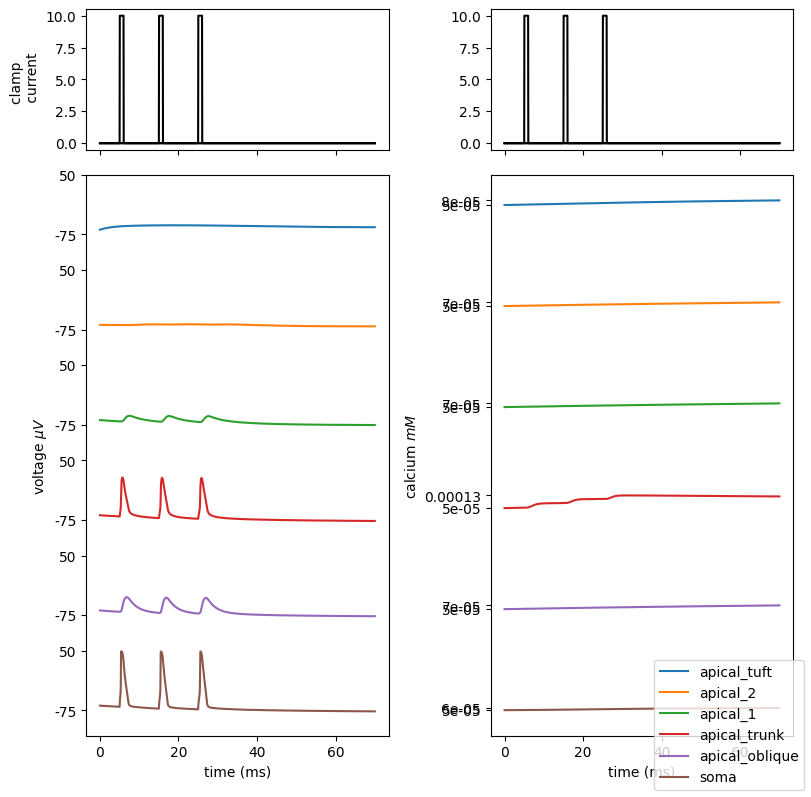

In [2]:
all_mechs = ['pas', 'NaT', 'SKv3_1', 'Nap_Et2', 'Ca_HVA', 'Ca_LVAst', 'CaDynamics_E2', 'Ih', 'Im','SK_E2', 'K_Pst', 'K_Tst']

l5pyr= Cell(sections, cell_tree, gid=0)
l5pyr.build()
add_mech = Mechs('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/model_db_hay/mod')
l5pyr = add_mech.add_mechs(l5pyr, hotzone=[1500, 2000])

num_pulse = 3
stim = [None]*num_pulse
clamp_current = [None]*num_pulse
for i in range(num_pulse):
    stim[i] = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
    stim[i].delay = 5+(10*i)
    stim[i].dur = 1
    stim[i].amp = 10
    clamp_current[i] = h.Vector().record(stim[i]._ref_i)

fig = fig_compartments(l5pyr, clamp_current, l_stim=70)
fig.savefig(figpth+f'rich_sections_{str(num_pulse)}_pulses_normal_Ih.png')

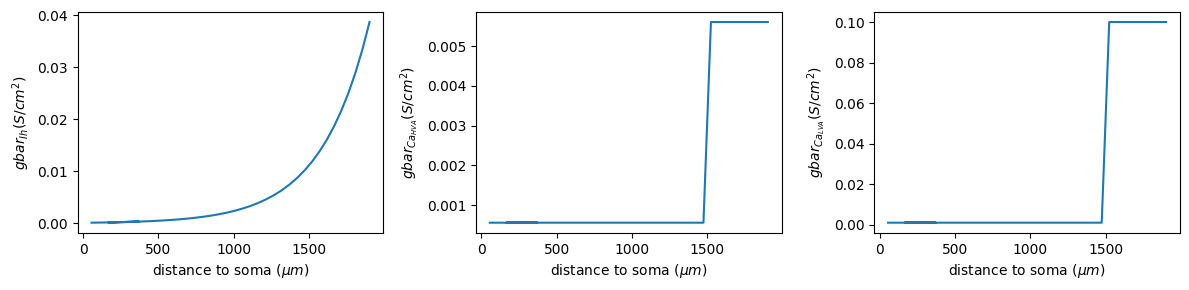

In [3]:
fig = fig_conductances(l5pyr)
fig.savefig('rich_distribution_conductances.png')